<a id='1'></a>
## 1. 🔧 Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

import lightgbm as lgb

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['figure.dpi'] = 100

COLORS = {'primary': '#DC3545', 'secondary': '#1A5276', 'accent': '#F39C12',
          'lr': '#9B59B6', 'dt': '#E67E22', 'lgbm': '#2ECC71'}
SEED = 42
print('✅ All libraries loaded!')

✅ All libraries loaded!


In [2]:
import os
DATA = 'data/istanbul_apartment_prices_2026.csv'
if not os.path.exists(DATA):  # e.g. opened from Colab: read the file straight from GitHub
    DATA = 'https://raw.githubusercontent.com/dorukozcan/istanbul-apartment-price-prediction/main/' + DATA
df = pd.read_csv(DATA)
print(f'Dataset: {df.shape[0]:,} rows × {df.shape[1]} columns')
df.head(3)

Dataset: 24,767 rows × 30 columns


,listing_id,price,price_per_sqm,district,neighborhood,rooms,halls,total_rooms,gross_sqm,net_sqm,...,usage_status,is_in_complex,complex_name,orientation,maintenance_fee,credit_eligible,deed_status,exchange,last_updated,scraped_at
0,54895-1121,15900000,165625.00,Adalar,Maden,3,1,4,138.0,96.0,...,Vacant,0,NaN,"North, South, East, West",2500.0,Not Eligible,Land Title,No,2026-03-11,2026-03-14T20:38:29
1,54895-1103,40000000,266666.67,Adalar,Nizam,4,1,5,199.0,150.0,...,Vacant,1,NaN,"North, South, East, West",10000.0,Eligible,Construction Easement,No,2026-03-05,2026-03-14T20:38:36
2,54895-1148,17850000,220370.37,Adalar,Nizam,2,1,3,107.0,81.0,...,Vacant,0,NaN,"North, East, West",1000.0,Eligible,Condominium Title,No,2026-03-05,2026-03-14T20:38:47


<a id='2'></a>
## 2. 🧹 Data Preparation — Guided by EDA

Our EDA revealed three key issues:
1. **Extreme price outliers** — 9 listings above ₺500M are likely data entry errors
2. **Right-skewed target** — skewness of ~63 requires log-transform
3. **Six columns >50% missing** — too sparse to impute reliably

In [3]:
# STEP 1: Remove extreme outliers (EDA Section 4)
p01, p99 = df['price'].quantile(0.01), df['price'].quantile(0.99)
print(f'Price range before: ₺{df["price"].min():,.0f} — ₺{df["price"].max():,.0f}')
print(f'Clipping to 1st-99th percentile: ₺{p01:,.0f} — ₺{p99:,.0f}')
df = df[(df['price'] >= p01) & (df['price'] <= p99)].copy()

# Remove unrealistic areas and room counts (EDA Section 6)
df = df[(df['gross_sqm'] >= 20) & (df['gross_sqm'] <= 500)].copy()
df = df[(df['net_sqm'] >= 15) & (df['net_sqm'] <= 450)].copy()
df = df[df['rooms'] <= 10].copy()
print(f'Rows after cleaning: {len(df):,}')

Price range before: ₺24,000 — ₺11,500,000,000
Clipping to 1st-99th percentile: ₺1,625,000 — ₺76,000,000
Rows after cleaning: 24,250


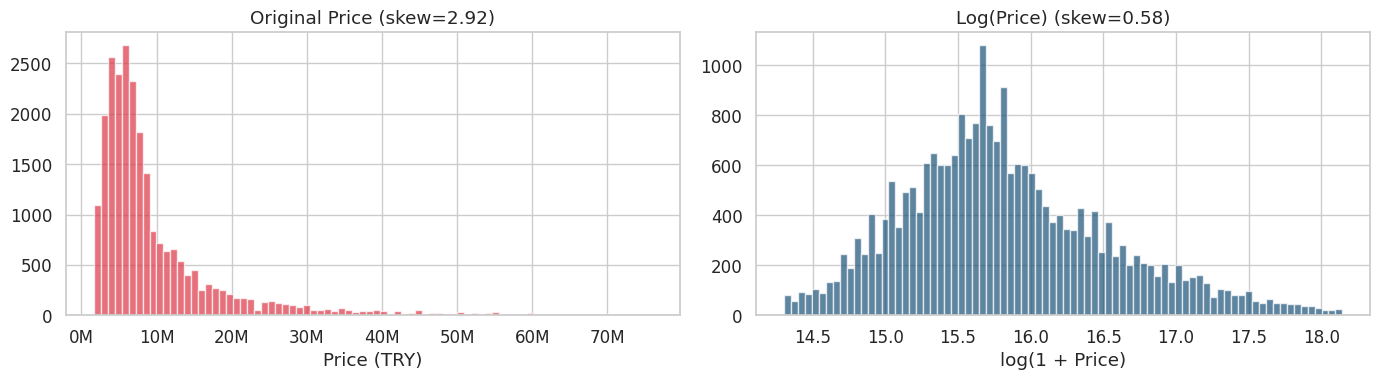

📊 Skewness: 2.92 → 0.58 after log transform


In [4]:
# STEP 2: Log-transform target (EDA Section 4)
df['log_price'] = np.log1p(df['price'])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(df['price'], bins=80, color=COLORS['primary'], alpha=0.7, edgecolor='white')
axes[0].set_title(f'Original Price (skew={df["price"].skew():.2f})')
axes[0].set_xlabel('Price (TRY)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.0f}M'))
axes[1].hist(df['log_price'], bins=80, color=COLORS['secondary'], alpha=0.7, edgecolor='white')
axes[1].set_title(f'Log(Price) (skew={df["log_price"].skew():.2f})')
axes[1].set_xlabel('log(1 + Price)')
plt.tight_layout()
plt.show()
print(f'📊 Skewness: {df["price"].skew():.2f} → {df["log_price"].skew():.2f} after log transform')

In [5]:
# STEP 3: Feature selection (EDA Section 3)
# Drop: id, leaky feature, >50% null, metadata
drop_cols = ['listing_id', 'price', 'price_per_sqm', 'complex_name', 'floor_category',
             'building_type', 'building_condition', 'fuel_type', 'maintenance_fee',
             'last_updated', 'scraped_at']
df_model = df.drop(columns=drop_cols, errors='ignore').copy()
target = 'log_price'
print(f'📊 Kept {df_model.shape[1] - 1} features, dropped {len(drop_cols)} columns')
print(f'\n⚠️ Why drop price_per_sqm?')
print(f'   price_per_sqm = price / gross_sqm → target leakage!')

📊 Kept 19 features, dropped 11 columns

⚠️ Why drop price_per_sqm?
   price_per_sqm = price / gross_sqm → target leakage!


<a id='3'></a>
## 3. ⚙️ Feature Engineering — From Insights to Features

Every feature below is motivated by a specific EDA finding:

In [6]:
# EDA §6: Net/gross ratio ~77% — space efficiency
df_model['net_gross_ratio'] = df_model['net_sqm'] / df_model['gross_sqm']
# EDA §6: Larger apartments have lower price/m²
df_model['sqm_per_room'] = df_model['gross_sqm'] / df_model['total_rooms'].clip(lower=1)
# EDA §7: Higher floors = higher prices
df_model['floor_ratio'] = df_model['floor'] / df_model['total_floors'].clip(lower=1)
# EDA §7: New buildings command premium
df_model['is_new'] = (df_model['building_age'] == 0).astype(int)
# EDA §7: High-rise apartments behave differently
df_model['is_high_floor'] = (df_model['floor'] > 10).astype(int)
# EDA §6: Room count categorical grouping
df_model['room_category'] = df_model['rooms'].clip(upper=5).astype(str)
df_model.loc[df_model['rooms'] > 5, 'room_category'] = '6+'
# EDA §7: Non-linear age effect
df_model['age_bin'] = pd.cut(df_model['building_age'], bins=[-1, 0, 5, 10, 20, 50, 500],
    labels=['New', '1-5y', '6-10y', '11-20y', '21-50y', '50y+']).astype(str)
# EDA §8: Orientation count
df_model['orientation_count'] = df_model['orientation'].apply(
    lambda x: len(str(x).split(',')) if pd.notna(x) else 0)
# EDA §9: District × Rooms interaction
df_model['district_room_key'] = df_model['district'] + '_' + df_model['rooms'].astype(str)

print('✅ 9 features engineered from EDA insights:\n')
for feat in ['net_gross_ratio', 'sqm_per_room', 'floor_ratio', 'is_new',
             'is_high_floor', 'room_category', 'age_bin', 'orientation_count', 'district_room_key']:
    print(f'  {feat:25s} unique: {df_model[feat].nunique():>5}')

✅ 9 features engineered from EDA insights:

  net_gross_ratio           unique:  2074
  sqm_per_room              unique:   586
  floor_ratio               unique:   300
  is_new                    unique:     2
  is_high_floor             unique:     2
  room_category             unique:     6
  age_bin                   unique:     6
  orientation_count         unique:     5
  district_room_key         unique:   237


In [7]:
# Encode categoricals & handle nulls
cat_cols = df_model.select_dtypes(include='object').columns.tolist()
if target in cat_cols: cat_cols.remove(target)
num_cols = df_model.select_dtypes(include=[np.number]).columns.tolist()
if target in num_cols: num_cols.remove(target)

for col in cat_cols: df_model[col] = df_model[col].fillna('Unknown')
for col in num_cols:
    if df_model[col].isna().sum() > 0:
        df_model[col] = df_model[col].fillna(df_model[col].median())
        print(f'  Filled {col} NaN with median')

feature_cols = [c for c in df_model.columns if c != target]
le_dict = {}
df_encoded = df_model.copy()
for col in cat_cols:
    le = LabelEncoder()
    df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
    le_dict[col] = le

X = df_encoded[feature_cols]; y = df_encoded[target]
X_cat = df_model[feature_cols].copy(); y_cat = df_model[target].copy()
cat_feature_indices = [X_cat.columns.get_loc(c) for c in cat_cols if c in X_cat.columns]
print(f'\n✅ Ready: {X.shape[1]} features, {len(X):,} samples')

  Filled floor NaN with median
  Filled total_floors NaN with median
  Filled bathroom_count NaN with median
  Filled floor_ratio NaN with median

✅ Ready: 28 features, 24,250 samples


<a id='4'></a>
## 4. 🏆 Model Tournament — Linear Regression vs Decision Tree vs LightGBM

We train three models of increasing complexity:
1. **Linear Regression** — simple baseline, assumes linear relationships
2. **Decision Tree** (`max_depth=6`) — captures non-linearity, capped depth to prevent overfitting
3. **LightGBM** — gradient boosting; expected to win based on EDA's non-linear patterns

Since our target is `log_price`, we invert predictions with `np.expm1()` before computing metrics in **original TRY scale**.

In [8]:
# ── Train / Test Split (80-20) ──────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

print(f'🔹 Training set : {X_train.shape[0]:,} samples')
print(f'🔹 Test set     : {X_test.shape[0]:,} samples')
print(f'🔹 Features     : {X_train.shape[1]}')

🔹 Training set : 19,400 samples
🔹 Test set     : 4,850 samples
🔹 Features     : 28


In [9]:
# ── Define & Train Models ──────────────────────────────────────────
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree (depth=6)': DecisionTreeRegressor(max_depth=6, random_state=SEED),
    'LightGBM': lgb.LGBMRegressor(random_state=SEED, verbose=-1)
}

# Train all models
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f'✅ {name} — trained')

✅ Linear Regression — trained


✅ Decision Tree (depth=6) — trained


✅ LightGBM — trained


In [10]:
# ── Evaluate on Original TRY Scale ────────────────────────────────
# Convert log-scale back to original prices
y_test_real = np.expm1(y_test)   # ground truth in TRY

results = []
for name, model in models.items():
    y_pred_log = model.predict(X_test)
    y_pred_real = np.expm1(y_pred_log)  # predictions in TRY

    mae  = mean_absolute_error(y_test_real, y_pred_real)
    rmse = np.sqrt(mean_squared_error(y_test_real, y_pred_real))
    r2   = r2_score(y_test_real, y_pred_real)
    mape = mean_absolute_percentage_error(y_test_real, y_pred_real) * 100

    results.append({
        'Model': name,
        'MAE (₺)': f'{mae:,.0f}',
        'RMSE (₺)': f'{rmse:,.0f}',
        'R² Score': f'{r2:.4f}',
        'MAPE (%)': f'{mape:.2f}'
    })

df_results = pd.DataFrame(results)
print('\n📊 Model Comparison — Original TRY Price Scale\n')
print(df_results.to_string(index=False))


📊 Model Comparison — Original TRY Price Scale

                  Model   MAE (₺)  RMSE (₺) R² Score MAPE (%)
      Linear Regression 4,192,394 7,856,768   0.3386    40.34
Decision Tree (depth=6) 3,906,839 7,240,735   0.4383    38.72
               LightGBM 2,276,012 4,514,059   0.7817    20.98


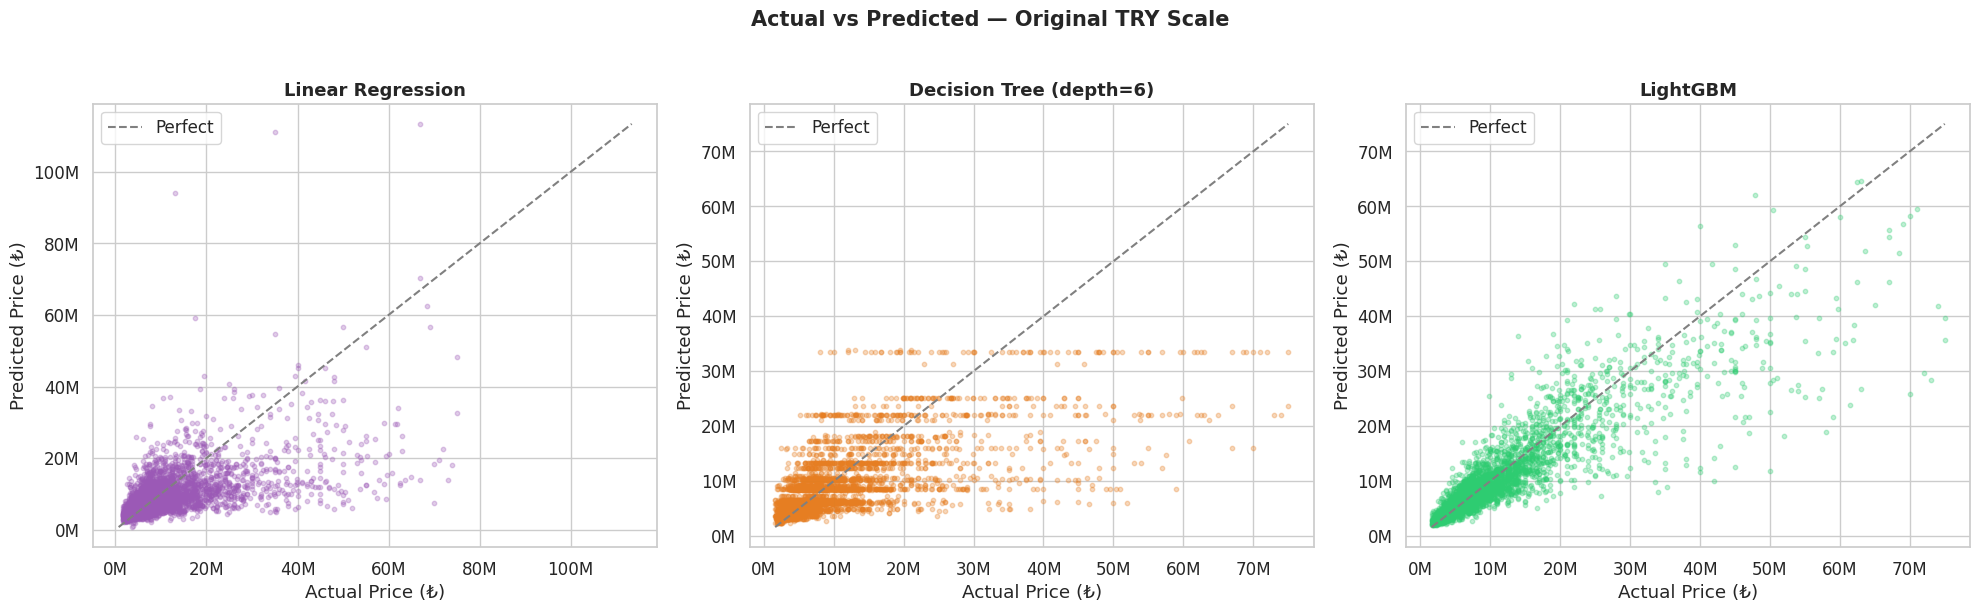

In [11]:
# ── Visual Comparison ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
model_colors = ['#9B59B6', '#E67E22', '#2ECC71']  # purple, orange, green

for ax, (name, model), color in zip(axes, models.items(), model_colors):
    y_pred_real = np.expm1(model.predict(X_test))
    ax.scatter(y_test_real, y_pred_real, alpha=0.3, s=10, color=color)
    # Perfect prediction line
    lims = [min(y_test_real.min(), y_pred_real.min()),
            max(y_test_real.max(), y_pred_real.max())]
    ax.plot(lims, lims, '--', color='gray', linewidth=1.5, label='Perfect')
    ax.set_title(name, fontsize=13, fontweight='bold')
    ax.set_xlabel('Actual Price (₺)')
    ax.set_ylabel('Predicted Price (₺)')
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.0f}M'))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.0f}M'))
    ax.legend()

plt.suptitle('Actual vs Predicted — Original TRY Scale', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

<a id='5'></a>
## 5. 🔍 Interpretation & Evaluation — Deep Dive into LightGBM

Four complementary analyses to validate our best model:
1. **Feature Importance** — Which variables drive predictions?
2. **5-Fold Cross-Validation** — Is the R² stable across different splits?
3. **Residual Analysis** — Are prediction errors randomly distributed?
4. **Anomaly Detection** — Which listings are priced far above or below the model's estimate?

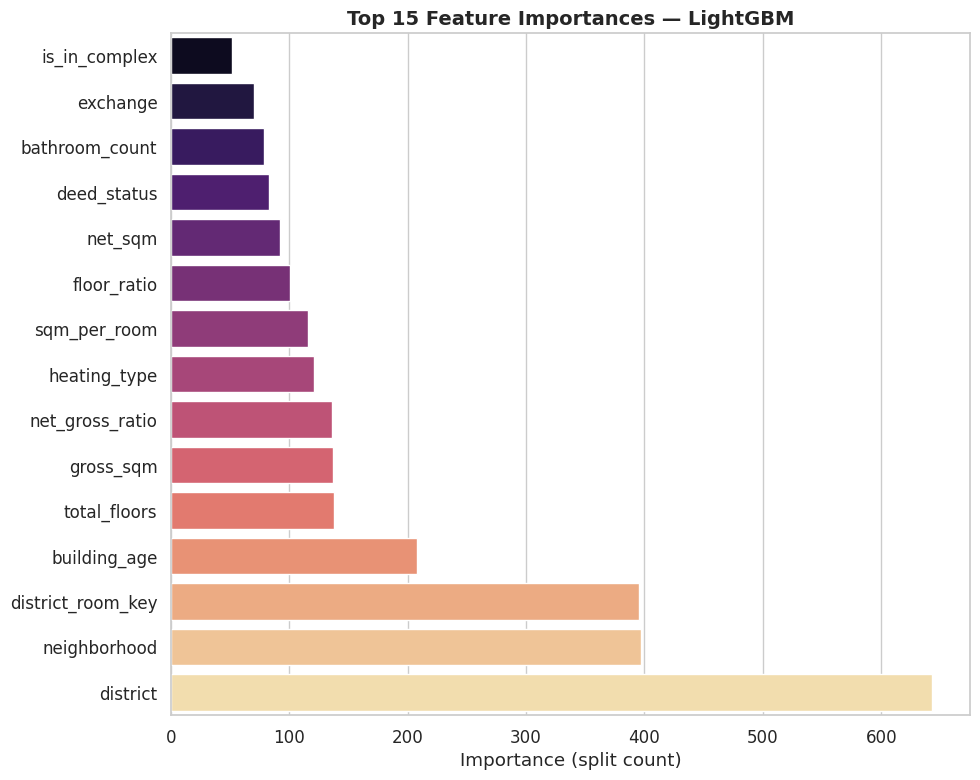


📊 Top 5 features:
   district                        →  643
   neighborhood                    →  397
   district_room_key               →  395
   building_age                    →  208
   total_floors                    →  138


In [12]:
# ── 5.1  Feature Importance (LightGBM) ───────────────────────────
lgbm_model = models['LightGBM']

feat_imp = pd.DataFrame({
    'Feature': X.columns,
    'Importance': lgbm_model.feature_importances_
}).sort_values('Importance', ascending=False)

top15 = feat_imp.head(15).sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(data=top15, x='Importance', y='Feature', palette='magma', ax=ax)
ax.set_title('Top 15 Feature Importances — LightGBM', fontsize=14, fontweight='bold')
ax.set_xlabel('Importance (split count)')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

print('\n📊 Top 5 features:')
for _, row in feat_imp.head(5).iterrows():
    print(f"   {row['Feature']:30s}  →  {row['Importance']:,.0f}")

In [13]:
# ── 5.2  5-Fold Cross-Validation (LightGBM) ──────────────────────
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

cv_scores = cross_val_score(
    lgb.LGBMRegressor(random_state=SEED, verbose=-1),
    X, y, cv=kf, scoring='r2'
)

print('📊 5-Fold Cross-Validation Results (R² Score)\n')
print('─' * 35)
for i, score in enumerate(cv_scores, 1):
    print(f'   Fold {i}:  R² = {score:.4f}')
print('─' * 35)
print(f'   Mean :  R² = {cv_scores.mean():.4f}  ± {cv_scores.std():.4f}')
print(f'\n✅ Model is {"stable" if cv_scores.std() < 0.01 else "moderately stable"} across folds.')

📊 5-Fold Cross-Validation Results (R² Score)

───────────────────────────────────
   Fold 1:  R² = 0.8520
   Fold 2:  R² = 0.8454
   Fold 3:  R² = 0.8436
   Fold 4:  R² = 0.8535
   Fold 5:  R² = 0.8451
───────────────────────────────────
   Mean :  R² = 0.8479  ± 0.0040

✅ Model is stable across folds.


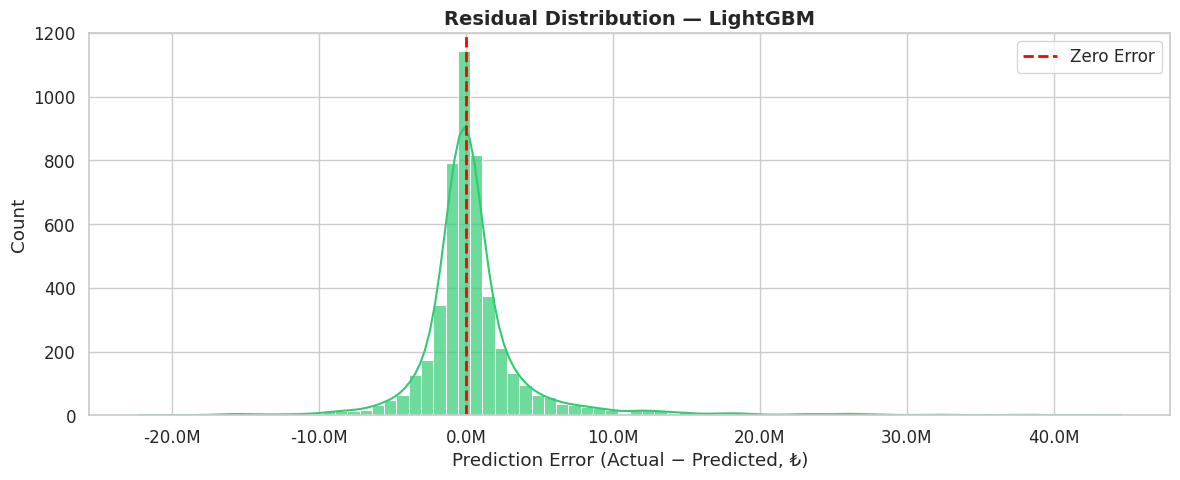


📊 Residual Statistics:
   Mean Error  : ₺        574,266
   Median Error: ₺        -17,397
   Std Dev     : ₺      4,477,844


In [14]:
# ── 5.3  Residual Analysis (LightGBM) ────────────────────────────
y_pred_lgbm = np.expm1(lgbm_model.predict(X_test))
residuals = y_test_real - y_pred_lgbm

fig, ax = plt.subplots(figsize=(12, 5))
sns.histplot(residuals, bins=80, kde=True, color=COLORS['lgbm'], alpha=0.7, ax=ax)
ax.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Zero Error')
ax.set_title('Residual Distribution — LightGBM', fontsize=14, fontweight='bold')
ax.set_xlabel('Prediction Error (Actual − Predicted, ₺)')
ax.set_ylabel('Count')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
ax.legend()
plt.tight_layout()
plt.show()

print(f'\n📊 Residual Statistics:')
print(f'   Mean Error  : ₺{residuals.mean():>15,.0f}')
print(f'   Median Error: ₺{residuals.median():>15,.0f}')
print(f'   Std Dev     : ₺{residuals.std():>15,.0f}')

In [15]:
# ── 5.4 Anomaly Detection ─────────────────────────────────────────────
anomaly_df = X_test.copy()
anomaly_df['Real_Price'] = y_test_real.values
anomaly_df['Predicted_Price'] = y_pred_lgbm
anomaly_df['Residual_Error'] = residuals.values

# Decode label-encoded columns back to readable names
for col, le in le_dict.items():
    if col in anomaly_df.columns:
        anomaly_df[col] = le.inverse_transform(anomaly_df[col].astype(int))

# Display columns
show_cols = ['district', 'neighborhood', 'Real_Price', 'Predicted_Price', 'Residual_Error']

# Format helper
fmt = {
    'Real_Price': '₺{:,.0f}',
    'Predicted_Price': '₺{:,.0f}',
    'Residual_Error': '₺{:,.0f}'
}

# ── Top 5 Overpriced (Balon / Pahalı) ──
overpriced = anomaly_df.sort_values('Residual_Error', ascending=False).head(5)[show_cols].copy()
print('🔴 Top 5 Overpriced Listings (Bubble / Expensive)')
print('   Real price far exceeds the model\'s fair-value estimate\n')
display(overpriced.style.format(fmt).hide(axis='index'))

print()

# ── Top 5 Underpriced (Fırsat / Ucuz) ──
underpriced = anomaly_df.sort_values('Residual_Error', ascending=True).head(5)[show_cols].copy()
print('🟢 Top 5 Underpriced Listings (Opportunity / Cheap)')
print('   Real price is well below the predicted value\n')
display(underpriced.style.format(fmt).hide(axis='index'))

🔴 Top 5 Overpriced Listings (Bubble / Expensive)
   Real price far exceeds the model's fair-value estimate



district,neighborhood,Real_Price,Predicted_Price,Residual_Error
Sarıyer,Rumeli Hisarı,"₺73,000,000","₺28,407,861","₺44,592,139"
Beşiktaş,Kuruçeşme,"₺70,000,000","₺25,891,897","₺44,108,103"
Kadıköy,Bostancı,"₺72,000,000","₺29,659,535","₺42,340,465"
Kadıköy,Suadiye,"₺75,000,000","₺35,603,211","₺39,396,789"
Üsküdar,Kuzguncuk,"₺58,000,000","₺19,012,460","₺38,987,540"



🟢 Top 5 Underpriced Listings (Opportunity / Cheap)
   Real price is well below the predicted value



district,neighborhood,Real_Price,Predicted_Price,Residual_Error
Şişli,Halide Edip Adıvar,"₺14,000,000","₺36,314,425","₺-22,314,425"
Sarıyer,Zekeriyaköy,"₺22,000,000","₺42,197,323","₺-20,197,323"
Beşiktaş,Yıldız,"₺21,000,000","₺39,368,752","₺-18,368,752"
Bahçelievler,Bahçelievler,"₺19,000,000","₺36,686,264","₺-17,686,264"
Bakırköy,Yeşilköy,"₺13,000,000","₺29,479,925","₺-16,479,925"
